# Predicting the next turn's speech features: transformer vs recurrent network

**Research question.** Is it possible to train a transformer to predict the speech features of the upcoming turn in a conversation so that it outperforms a recurrent neural network?

**Why it might help.** A recurrent network has to carry everything it knows about the conversation in one state vector that it updates turn by turn. A transformer can attend directly to any earlier turn, for example the other speaker's last turn, which may matter for predicting how they will sound next. Suggested by Prof. Matthew McNeill.

## Setup

- **Data:** the Fisher corpus of telephone conversations, preprocessed into one row per turn. The file is licensed to the institution, so it lives in `data/fisher/`, which is git-ignored. It is never committed.
- **Task:** for every conversation, use turns 1..t to predict the 7 speech features of turn t+1:

| feature | what it measures |
|---|---|
| `pitch_mean_log` | how high the voice is (log₁₀ Hz) |
| `pitch_std_log` | how much the pitch varies within the turn |
| `intensity_mean` | loudness (dB) |
| `jitter` | cycle-to-cycle variation in pitch |
| `shimmer` | cycle-to-cycle variation in loudness |
| `nhr` | noise-to-harmonics ratio (breathiness, hoarseness) |
| `rate_syl_sec` | speaking rate (syllables per second) |

## Main experiment: transformer vs recurrent network

Every model sees the **speech features** of the past turns (the 7 features, a missing flag for each, and the speaker):

| model | role |
|---|---|
| GRU | recurrent network |
| GRU + attention | recurrent network that can also look back at its earlier states |
| causal transformer | the model being tested |
| training mean, previous turn | baselines: simple rules with nothing learned |
| last-turn linear model | simple learned reference: sees only the most recent turn, so it shows what the rest of the conversation adds |

Section 14 then tunes the size of each model, with a learning-rate warmup, to give the transformer its best chance.

## Extension: do the words add anything?

The same models are trained twice more, on two other inputs, to see how the speech features compare with what is said:

| version | input for each past turn | question it answers |
|---|---|---|
| words + speech features | the features plus attention over the turn's words | does adding words help? |
| words only | attention over the turn's words (+ speaker) | how much does the content alone predict? |

If words + speech features beats words only, the speech features carry predictive information that the words don't. Sections 4 and 13 are part of this extension; everything else serves the main experiment.


## Settings carried over from earlier work, and what changed

| setting | used here? | why |
|---|---|---|
| the 7 features, split by `conv_id`, zero-padded start turn | yes | the task definition |
| transformer vs recurrent network | yes | the main research question |
| **bidirectional RNN** | **no** | A bidirectional model also reads the conversation backwards, so its output at turn t would already contain turn t+1, the turn it is supposed to predict. It worked for IMDB because the whole review is available before classifying it. Here we predict the future, so every model must be *causal*. Section 7 tests this. |
| 25 epochs | replaced | The IMDB models overfit after 5–11 epochs. Here training stops once validation loss hasn't improved for 3 epochs (at most 100), and the best epoch is chosen by validation **loss**. That fixes the flaw noted in the IMDB notebook, where it was chosen by accuracy. |
| learning rate 3e-4 | tried, alongside 1e-3 | Each model is trained with both, and the one with the lower validation loss is kept. Transformers often need a lower learning rate than GRUs, so one shared value could favor one architecture. |
| half precision | yes, on the NVIDIA GPU | bf16 autocast. On the Mac CPU it was slower, so it is only turned on when a CUDA GPU is present. Section 8 measures the speed-up. |

## 1. Setup

In [1]:
import math
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader

from fisher_data import (FEATURES, N_FEAT, PAD_ID, UNK_ID, ConversationDataset, build_conversations,
                         build_vocab, collate_conversations, load_turns, split_conversations)
from imdb_data import BucketBatchSampler

SMOKE_TEST = os.environ.get("FISHER_SMOKE") == "1"  # small run used to check the notebook end to end
SEED = 0
torch.manual_seed(SEED)
np.random.seed(SEED)

# CUDA when available (the NVIDIA laptop), otherwise CPU. Not MPS: on this Mac the MPS backend leaked
# memory on GRUs and on transformers with varying sequence lengths (see the IMDB experiment log).
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# Half precision (bf16 autocast) only on an NVIDIA GPU: on the Mac CPU it made training slower (IMDB notebook).
USE_BF16 = device.type == "cuda" and torch.cuda.is_bf16_supported()
print("device:", device, torch.cuda.get_device_name(0) if device.type == "cuda" else "",
      "| bf16:", USE_BF16, "| torch", torch.__version__, "| smoke test:", SMOKE_TEST)

device: cuda NVIDIA GeForce RTX 4050 Laptop GPU | bf16: True | torch 2.11.0+cu128 | smoke test: False


## 2. Load and check the data

The data is checked up front, so the rest of the notebook can rely on these facts instead of guarding against problems in the model code.

In [2]:
turns = load_turns("data/fisher/fisher_data_simple.csv")
print(f"{len(turns):,} turns in {turns.conv_id.nunique():,} conversations")
turns.head()

In [3]:
by_conv = turns.groupby("conv_id")["turn_id"]
turn_counts = by_conv.size()
assert (by_conv.min() == 1).all(), "every conversation starts at turn 1"
assert ((by_conv.max() - by_conv.min() + 1) == turn_counts).all(), "no gaps in turn_id"
assert not turns.duplicated(["conv_id", "turn_id"]).any(), "no duplicate turns"
assert set(turns.side) == {"A", "B"}

print("turns per conversation:", turn_counts.describe().round(1).to_dict())
same_speaker = (turns.side == turns.groupby("conv_id").side.shift()).mean()
print(f"turns spoken by the same person as the previous turn: {same_speaker:.1%}")

turns per conversation: {'count': 10998.0, 'mean': 188.8, 'std': 37.5, 'min': 54.0, '25%': 163.0, '50%': 187.0, '75%': 211.8, 'max': 456.0}
turns spoken by the same person as the previous turn: 35.9%


**Speakers don't strictly alternate.** About a third of turns come from the same person as the turn before. So each turn's speaker (A or B) is given to the models as a one-hot input. It isn't a speech feature, and it is part of every version.

### Missing values

Some turns are missing features. `load_turns` already treats a speaking rate of exactly 0 as missing. Those turns have no recognized words, so the rate is undefined rather than zero.

In [4]:
missing = turns[FEATURES].isna()
summary = pd.DataFrame({
    "missing turns": missing.sum(),
    "missing %": (100 * missing.mean()).round(2),
    "mean": turns[FEATURES].mean().round(4),
    "std": turns[FEATURES].std().round(4),
})
display(summary)
no_text = turns.text.isna()
print(f"turns missing at least one feature: {missing.any(axis=1).sum():,} ({missing.any(axis=1).mean():.1%})")
print(f"turns missing all 7 features:       {missing.all(axis=1).sum():,}  (of these, {no_text[missing.all(axis=1)].mean():.0%} have no text)")
print(f"turns missing only the rate:        {(missing.rate_syl_sec & ~missing.drop(columns='rate_syl_sec').any(axis=1)).sum():,}")
print(f"conversations with a missing value: {turns.loc[missing.any(axis=1), 'conv_id'].nunique() / turns.conv_id.nunique():.0%}")

,missing turns,missing %,mean,std
pitch_mean_log,29321,1.41,2.2210,0.1320
pitch_std_log,29321,1.41,0.1001,0.0644
intensity_mean,29321,1.41,62.6245,7.5170
jitter,29651,1.43,0.0113,0.0056
shimmer,30383,1.46,0.1186,0.0384
nhr,29321,1.41,0.2156,0.1130
rate_syl_sec,65614,3.16,3.1596,1.4777


turns missing at least one feature: 78,870 (3.8%)
turns missing all 7 features:       16,903  (of these, 100% have no text)
turns missing only the rate:        48,487
conversations with a missing value: 96%


There are two kinds of missing turn:

1. **Nothing measurable** (all 7 features missing, no text): most likely laughter, a cough, noise, or a sound too short to measure.
2. **Voice measured, no words recognized** (only the rate missing): e.g. "mm-hmm", a sigh, or a filler sound. Pitch and loudness are real, but syllables per second can't be computed.

**How missing values are handled.** We keep every turn and tell the model honestly what is missing.

The alternatives are worse:
- Deleting the missing turns would make turn 6 look like it directly follows turn 4, breaking the conversation's order.
- Deleting conversations with any missing value would remove most of the dataset (see the last line above).

What we do instead:

- **As input:** a missing feature is set to the training average. That is 0 after standardizing (next section). A *missing flag* for each feature (1 = not measured) is added, so the model can tell a real average value (value 0, flag 0) from a placeholder (value 0, flag 1). The flags can also carry signal, e.g. "after laughter, the next turn tends to be louder".
- **As a target:** missing values are left out of the loss and the evaluation. The model is only ever scored on values that were actually measured. If only the rate is missing, the other 6 features are still scored.

This is done once, in the data preparation (`fisher_data.py`). The models need no special cases.

Example: a turn where someone says "mm-hmm" (voice measured, rate missing):

| | pitch | pitch var. | loudness | jitter | shimmer | nhr | rate |
|---|---|---|---|---|---|---|---|
| raw | 2.30 (200 Hz) | 0.08 | 60.0 dB | 0.010 | 0.110 | 0.20 | missing |
| value given to the model | +0.60 | −0.31 | −0.35 | −0.23 | −0.22 | −0.14 | **0.00** |
| missing flag | 0 | 0 | 0 | 0 | 0 | 0 | **1** |

## 3. Split by conversation and standardize

- **Split by `conv_id`:** 80% train, 10% validation, 10% test. A conversation is never split across sets. Otherwise the model would see part of a test conversation during training.
- **Standardize** each feature: (value − mean) ÷ std. The raw scales differ by a factor of thousands (loudness ≈ 62, jitter ≈ 0.01). After standardizing, every feature is centered on 0 with spread 1, so no feature dominates the loss just because its numbers are bigger. The mean and std come **from the training conversations only**, so nothing about the validation or test sets leaks into training.
- **Error unit:** all errors below are mean squared error in standardized units. Always predicting the training mean scores about 1.0, which makes it easy to read: 0.6 means the model removes 40% of the error of that trivial guess.

In [5]:
train_ids, val_ids, test_ids = split_conversations(turns.conv_id.unique(), seed=SEED)
if SMOKE_TEST:
    train_ids, val_ids, test_ids = (set(sorted(ids)[:n]) for ids, n in [(train_ids, 400), (val_ids, 100), (test_ids, 100)])
assert not (train_ids & val_ids) and not (train_ids & test_ids) and not (val_ids & test_ids)

train_turns = turns[turns.conv_id.isin(train_ids)]
feature_mean = train_turns[FEATURES].mean().to_numpy(np.float32)
feature_std = train_turns[FEATURES].std().to_numpy(np.float32)
print(f"conversations: train {len(train_ids):,} | val {len(val_ids):,} | test {len(test_ids):,}")
pd.DataFrame({"train mean": feature_mean, "train std": feature_std}, index=FEATURES).round(4)

conversations: train 8,798 | val 1,099 | test 1,101


,train mean,train std
pitch_mean_log,2.2210,0.1318
pitch_std_log,0.1001,0.0644
intensity_mean,62.5886,7.5382
jitter,0.0113,0.0055
shimmer,0.1186,0.0384
nhr,0.2153,0.1128
rate_syl_sec,3.1573,1.4757


## 4. Words (extension)

The two extension versions also see the words of each past turn. The transcripts are lowercase and split on spaces. The average turn has about 10 words, and the longest has 114.

- **Vocabulary** from the training conversations only.
- Words seen fewer than 5 times become a shared "unknown word" token. Very rare words can't be learned from a handful of examples. The turn and all its other words are kept.
- Turns with no transcript have no words. They still have their speech features and missing flags.

In [6]:
MIN_WORD_COUNT = 5
vocab = build_vocab(train_turns.text.dropna(), MIN_WORD_COUNT)
vocab_size = len(vocab) + 2
train_words = train_turns.text.dropna().str.split().explode()
print(f"vocabulary: {vocab_size:,} entries (incl. padding and unknown)")
print(f"share of training words that are in the vocabulary: {train_words.isin(set(vocab)).mean():.2%}")

vocabulary: 22,858 entries (incl. padding and unknown)


share of training words that are in the vocabulary: 99.64%


## 5. Building the sequences

**Start turn.** Following the suggestion to zero-pad the start of each conversation, a turn 0 is added at the beginning, so the first real turn can be predicted too. Its features are 0, all 7 missing flags are 1 ("nothing measured yet"), its speaker is neither A nor B, and it has no words.

**Shift.** For a conversation with T turns, the input is turns 0..T−1 and the target is turns 1..T. Position t of the output predicts turn t+1 using only turns 0..t. Each model is *causal*: its output at position t may not depend on any later input. This is tested in section 7.

Each input turn has 16 numbers: 7 standardized features, 7 missing flags, and 2 for the speaker.

In [7]:
splits = {name: build_conversations(turns, ids, feature_mean, feature_std, vocab)
          for name, ids in [("train", train_ids), ("val", val_ids), ("test", test_ids)]}

# Alignment check: the input at position t+1 is exactly the target at position t.
conv = splits["train"][0]
assert torch.equal(conv.inputs[1:, :N_FEAT], conv.targets[:-1])
assert torch.equal(conv.inputs[0, :N_FEAT], torch.zeros(N_FEAT)) and conv.inputs[0, N_FEAT:2 * N_FEAT].all()
assert conv.turn_lengths.sum() == len(conv.tokens)

# Standardization check on the training targets that were actually measured.
targets = torch.cat([c.targets for c in splits["train"]])
observed = torch.cat([c.observed for c in splits["train"]])
observed_mean = (targets * observed).sum(0) / observed.sum(0)
print("train target mean per feature (should be ~0):", observed_mean.numpy().round(3))
print("turns per split:", {k: sum(len(c) for c in v) for k, v in splits.items()})

train target mean per feature (should be ~0): [0. 0. 0. 0. 0. 0. 0.]
turns per split: {'train': 1657699, 'val': 208068, 'test': 210925}


In [8]:
BATCH_SIZE = 32  # conversations per batch (about 6,000 turns)


def make_loader(name, shuffle):
    conversations = splits[name]
    sampler = BucketBatchSampler([len(c) for c in conversations], BATCH_SIZE, shuffle=shuffle,
                                 drop_last=False, seed=SEED)
    return DataLoader(ConversationDataset(conversations), batch_sampler=sampler,
                      collate_fn=collate_conversations)


loaders = {"train": make_loader("train", True), "val": make_loader("val", False), "test": make_loader("test", False)}
batch = next(iter(loaders["train"]))
print({k: tuple(v.shape) for k, v in batch.items()})

{'inputs': (32, 169, 16), 'targets': (32, 169, 7), 'observed': (32, 169, 7), 'lengths': (32,), 'turn_type': (32, 169), 'tokens': (58745,), 'token_turn': (58745,)}


Batches group conversations of similar length (the length-bucketing sampler from the IMDB notebook), so little compute goes to padding. Padding sits at the end of each conversation. Because every model is causal, real positions never look at the padding after them, and padded targets are excluded from the loss by the `observed` mask.

## 6. Models

Every model has the same three parts:

1. **Turn encoder:** turns each past turn into one vector of size 128.
2. **Sequence model:** reads the turn vectors in order (GRU, GRU + attention, or transformer).
3. **Output layer:** 7 numbers, the predicted features of the next turn.

### Turn encoder and attention over words

Depending on the version, the turn vector is built from:
- the speaker (always)
- the 7 features and 7 missing flags (versions 1 and 2)
- a summary of the turn's words (versions 2 and 3).

**Attention over words.** Each word gets a learned embedding (64 numbers) and an attention score $s_i = v^\top \tanh(W e_i)$, the additive scoring from the attention notebook. The scores are softmaxed *within the turn*, and the turn's word vector is the weighted average of its embeddings. The model learns which words in a turn matter for predicting how the next turn will sound. A turn with no words gets a zero vector.

All words of a batch are kept in one flat list with the index of the turn they belong to, instead of padding every turn to 114 words.

In [9]:
class WordAttentionPool(nn.Module):
    def __init__(self, vocab_size, dim):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, dim, padding_idx=PAD_ID)
        self.W = nn.Linear(dim, dim)
        self.v = nn.Linear(dim, 1, bias=False)

    def forward(self, tokens, token_turn, n_turns):
        embedded = self.embedding(tokens)                                  # (words, dim)
        scores = self.v(torch.tanh(self.W(embedded))).squeeze(-1).float()  # (words,), float32 under bf16 autocast
        # Softmax within each turn: subtract the turn's max score for numerical stability.
        turn_max = torch.full((n_turns,), -math.inf, device=scores.device)
        turn_max = turn_max.scatter_reduce(0, token_turn, scores.detach(), "amax")
        weights = torch.exp(scores - turn_max[token_turn])
        totals = torch.zeros(n_turns, device=scores.device).index_add(0, token_turn, weights)
        weights = weights / totals[token_turn]
        pooled = torch.zeros(n_turns, embedded.shape[1], device=scores.device)
        pooled = pooled.index_add(0, token_turn, weights.unsqueeze(-1) * embedded)
        return pooled, weights


class TurnEncoder(nn.Module):
    def __init__(self, use_features, use_words, model_dim=128, word_dim=64):
        super().__init__()
        self.use_features, self.use_words = use_features, use_words
        in_dim = 2 + (2 * N_FEAT if use_features else 0) + (word_dim if use_words else 0)
        if use_words:
            self.words = WordAttentionPool(vocab_size, word_dim)
        self.proj = nn.Linear(in_dim, model_dim)

    def forward(self, batch):
        x = batch["inputs"]
        size, length, _ = x.shape
        parts = [x[..., 2 * N_FEAT:]]  # speaker
        if self.use_features:
            parts.append(x[..., :2 * N_FEAT])  # features and missing flags
        if self.use_words:
            pooled, _ = self.words(batch["tokens"], batch["token_turn"], size * length)
            parts.append(pooled.view(size, length, -1))
        return self.proj(torch.cat(parts, dim=-1))

### Sequence models

- **GRU:** one layer, hidden size 128, reading turn by turn. Padding isn't packed: padding comes after the real turns, and a one-direction GRU never looks ahead, so outputs at real positions are unchanged.
- **GRU + attention:** at each turn t, the GRU state $h_t$ attends over all GRU states so far ($h_0..h_t$), and the output uses both $h_t$ and the attention summary.
  - Scores are multiplicative, $h_t^\top W h_i / \sqrt{128}$, rather than additive.
  - Additive attention would build a vector for every (t, i) pair: 32 conversations × 457 × 457 pairs × 128 numbers is several GB. Multiplicative needs one number per pair.
  - A causal mask hides future turns.
- **Last-turn linear model:** the turn encoder followed directly by a linear output layer, with no sequence model. It predicts turn t+1 from turn t alone, so it shows what the conversation history adds. On speech features it is a linear function of the previous turn; with words it also sees the previous turn's attention-pooled words.
- **Causal transformer:**
  - 2 pre-LayerNorm layers (the variant discussed in the pre-norm reading), 4 heads, model size 128, feed-forward size 256, dropout 0.1, sinusoidal positions.
  - The causal mask stops turn t from attending to later turns.
  - It uses PyTorch's `nn.TransformerEncoderLayer`. The IMDB notebook built the same block from scratch and checked it against PyTorch's attention.

In [10]:
def causal_mask(length, device):
    # True above the diagonal = "may not attend" (future positions).
    return torch.triu(torch.ones(length, length, dtype=torch.bool, device=device), diagonal=1)


class GRUModel(nn.Module):
    def __init__(self, encoder, hidden=128, attention=False, dropout=0.1):
        super().__init__()
        self.encoder, self.attention = encoder, attention
        self.gru = nn.GRU(encoder.proj.out_features, hidden, batch_first=True)
        if attention:
            self.W = nn.Linear(hidden, hidden, bias=False)
        self.dropout = nn.Dropout(dropout)
        self.head = nn.Linear(2 * hidden if attention else hidden, N_FEAT)

    def forward(self, batch):
        h, _ = self.gru(self.encoder(batch))                           # (batch, length, hidden)
        if self.attention:
            scores = h @ self.W(h).transpose(1, 2) / math.sqrt(h.shape[-1])  # [t, i] = h_t . W h_i
            scores = scores.masked_fill(causal_mask(h.shape[1], h.device), -math.inf)
            context = torch.softmax(scores, dim=-1) @ h
            h = torch.cat([h, context], dim=-1)
        return self.head(self.dropout(h))


class CausalTransformer(nn.Module):
    def __init__(self, encoder, heads=4, layers=2, ff_dim=256, dropout=0.1, max_len=1024):
        super().__init__()
        self.encoder = encoder
        dim = encoder.proj.out_features
        layer = nn.TransformerEncoderLayer(dim, heads, ff_dim, dropout, batch_first=True, norm_first=True)
        self.blocks = nn.TransformerEncoder(layer, layers, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(dim)
        self.dropout = nn.Dropout(dropout)
        self.head = nn.Linear(dim, N_FEAT)
        position = torch.arange(max_len).unsqueeze(1)
        freq = torch.exp(torch.arange(0, dim, 2) * (-math.log(10000.0) / dim))
        pe = torch.zeros(max_len, dim)
        pe[:, 0::2], pe[:, 1::2] = torch.sin(position * freq), torch.cos(position * freq)
        self.register_buffer("positions", pe)

    def forward(self, batch):
        x = self.encoder(batch)
        length = x.shape[1]
        x = self.dropout(x + self.positions[:length])
        h = self.blocks(x, mask=causal_mask(length, x.device), is_causal=True)
        return self.head(self.norm(h))


class LastTurnLinear(nn.Module):
    # No history: the prediction for turn t+1 depends only on turn t.
    def __init__(self, encoder):
        super().__init__()
        self.encoder = encoder
        self.head = nn.Linear(encoder.proj.out_features, N_FEAT)

    def forward(self, batch):
        return self.head(self.encoder(batch))


VERSIONS = {"speech features": (True, False), "words + speech features": (True, True), "words only": (False, True)}
ARCHITECTURES = {
    "GRU": lambda enc: GRUModel(enc),
    "GRU + attention": lambda enc: GRUModel(enc, attention=True),
    "transformer": lambda enc: CausalTransformer(enc),
    "last-turn linear": lambda enc: LastTurnLinear(enc),
}


def make_model(version, architecture):
    use_features, use_words = VERSIONS[version]
    return ARCHITECTURES[architecture](TurnEncoder(use_features, use_words)).to(device)

## 7. Sanity checks

1. **Causality:** change everything after position k (features and words) and check that the outputs up to position k don't change. If this failed, a model could "see" the turn it is predicting. The check runs on the CPU: on the GPU, the word pooling adds numbers in a varying order, so even the *same* input can differ by about 1e-5 between runs, which is the size of the tolerance.
2. **Attention over words:** the weights within each turn that has words sum to 1.

In [11]:
def to_device(batch):
    return {k: v.to(device) for k, v in batch.items()}


def perturb_after(batch, k):
    changed = {key: value.clone() for key, value in batch.items()}
    changed["inputs"][:, k + 1:] = torch.randn_like(changed["inputs"][:, k + 1:])
    length = batch["inputs"].shape[1]
    later_words = (batch["token_turn"] % length) > k
    changed["tokens"][later_words] = torch.randint(2, vocab_size, (int(later_words.sum()),), device=batch["tokens"].device)
    return changed


check_batch = next(iter(loaders["val"]))  # stays on the CPU, where results are exactly repeatable
k = 20
for version in VERSIONS:
    for architecture in ARCHITECTURES:
        model = make_model(version, architecture).cpu().eval()
        with torch.no_grad():
            original = model(check_batch)
            changed = model(perturb_after(check_batch, k))
        assert torch.allclose(original[:, :k + 1], changed[:, :k + 1], atol=1e-5), (version, architecture)
        assert (original[:, k + 1:] - changed[:, k + 1:]).abs().max() > 1e-3, "later outputs should change"
print(f"causality check passed for all {len(VERSIONS) * len(ARCHITECTURES)} models: outputs up to turn k ignore everything after it")

pool = make_model("words only", "GRU").encoder.words.cpu()
size, length = check_batch["inputs"].shape[:2]
with torch.no_grad():
    _, weights = pool(check_batch["tokens"], check_batch["token_turn"], size * length)
sums = torch.zeros(size * length).index_add(0, check_batch["token_turn"], weights)
has_words = torch.bincount(check_batch["token_turn"], minlength=size * length) > 0
assert torch.allclose(sums[has_words], torch.ones_like(sums[has_words]), atol=1e-5)
print("word attention weights sum to 1 within every turn that has words")

causality check passed for all 12 models: outputs up to turn k ignore everything after it
word attention weights sum to 1 within every turn that has words


## 8. Training

- **Loss:** mean squared error over the measured target values only (the `observed` mask).
- **Optimizer:** Adam with gradient clipping at 1.0. Each model is trained at learning rates 1e-3 and 3e-4, and the one with the lower validation loss is kept. The test set is only used for the kept one.
- **Precision:** on the GPU, the forward pass runs in bf16 (autocast), while the loss and the weights stay in full precision.
- **Model selection:** the best epoch is chosen by **validation loss**, not accuracy-style metrics. The IMDB experiment showed why: picking by accuracy kept overconfident late epochs. Training stops early when validation loss hasn't improved for 3 epochs (at most 100 epochs).

In [12]:
LEARNING_RATES = [1e-3, 3e-4]
MAX_EPOCHS = 2 if SMOKE_TEST else 100
PATIENCE = 3


def autocast():
    return torch.autocast(device.type, dtype=torch.bfloat16, enabled=USE_BF16)


def evaluate(predict, loader):
    # Returns per-feature sum of squared errors and number of measured values.
    sse = torch.zeros(N_FEAT)
    count = torch.zeros(N_FEAT)
    with torch.no_grad():
        for batch in loader:
            batch = to_device(batch)
            observed = batch["observed"]
            with autocast():
                prediction = predict(batch)
            error = (prediction.float() - batch["targets"]) ** 2 * observed
            sse += error.sum(dim=(0, 1)).cpu()
            count += observed.sum(dim=(0, 1)).cpu()
    return sse, count


def mse(sse, count):
    return float(sse.sum() / count.sum())


def train_model(version, architecture, lr, build=None, warmup_steps=0):
    # build: optional function returning a model (used by the tuning sweep in section 14)
    # warmup_steps: the learning rate rises linearly from 0 over this many steps (0 = no warmup)
    torch.manual_seed(SEED)
    model = build() if build else make_model(version, architecture)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.LambdaLR(
        optimizer, lambda step: min(1.0, (step + 1) / warmup_steps) if warmup_steps else 1.0)
    history, best = [], (math.inf, None, 0)
    for epoch in range(1, MAX_EPOCHS + 1):
        start = time.time()
        model.train()
        train_sse, train_count = 0.0, 0.0
        for batch in loaders["train"]:
            batch = to_device(batch)
            observed = batch["observed"]
            with autocast():
                prediction = model(batch)
            squared = (prediction.float() - batch["targets"]) ** 2 * observed  # loss in full precision
            loss = squared.sum() / observed.sum()
            optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            scheduler.step()
            train_sse += squared.detach().sum().item()
            train_count += observed.sum().item()
        model.eval()
        val_loss = mse(*evaluate(model, loaders["val"]))
        history.append({"epoch": epoch, "train": train_sse / train_count, "val": val_loss, "seconds": time.time() - start})
        print(f"  epoch {epoch:2d}  train {history[-1]['train']:.4f}  val {val_loss:.4f}  ({history[-1]['seconds']:.0f}s)")
        if val_loss < best[0]:
            best = (val_loss, {k: v.detach().clone() for k, v in model.state_dict().items()}, epoch)
        elif epoch - best[2] >= PATIENCE:
            break
    model.load_state_dict(best[1])
    model.eval()
    return model, pd.DataFrame(history), best[2]

### Half precision: does it speed up training?

Time 30 training steps per architecture (version 1 inputs, a typical batch), in full precision (fp32) and in bf16. This only runs on the NVIDIA GPU. On the Mac CPU, bf16 was slower (IMDB notebook).

In [13]:
def time_steps(architecture, use_bf16, steps=30):
    torch.manual_seed(SEED)
    model = make_model("speech features", architecture).train()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    batch = to_device(next(iter(loaders["train"])))
    for i in range(steps + 5):  # first 5 steps are warm-up
        if i == 5:
            torch.cuda.synchronize()
            start = time.time()
        with torch.autocast("cuda", dtype=torch.bfloat16, enabled=use_bf16):
            prediction = model(batch)
        loss = (((prediction.float() - batch["targets"]) ** 2) * batch["observed"]).sum() / batch["observed"].sum()
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    torch.cuda.synchronize()
    return 1000 * (time.time() - start) / steps


if device.type == "cuda":
    timing = pd.DataFrame([{"architecture": a, "fp32 ms/step": time_steps(a, False), "bf16 ms/step": time_steps(a, True)}
                           for a in ARCHITECTURES])
    timing["speed-up"] = (timing["fp32 ms/step"] / timing["bf16 ms/step"]).round(2)
    display(timing.round(1))
else:
    print("No CUDA GPU: skipped. Training runs in fp32.")

,architecture,fp32 ms/step,bf16 ms/step,speed-up
0,GRU,3.0,3.8,0.8
1,GRU + attention,5.3,7.4,0.7
2,transformer,10.7,10.2,1.0
3,last-turn linear,2.5,3.2,0.8


## 9. Baselines

A model is only useful if it beats simple rules. There are two:

- **Training mean:** always predict the average turn. This scores about 1.0 by construction.
- **Previous turn:** predict that the next turn sounds exactly like the last one. Before the first turn, and for features that weren't measured, it falls back to the average.

Copying the last turn copies its noise too, so a fairer simple reference is the **last-turn linear model**, which learns how much to trust the last turn. It is trained like the other models, so it appears with them in section 10.

In [14]:
results = []
baselines = {
    "training mean": lambda batch: torch.zeros_like(batch["targets"]),
    "previous turn": lambda batch: batch["inputs"][..., :N_FEAT],
}
for name, predict in baselines.items():
    val_sse, val_count = evaluate(predict, loaders["val"])
    test_sse, test_count = evaluate(predict, loaders["test"])
    results.append({"version": "baseline", "model": name, "params": 0, "lr": None, "best epoch": None,
                    "val MSE": mse(val_sse, val_count), "test MSE": mse(test_sse, test_count),
                    **dict(zip(FEATURES, (test_sse / test_count).numpy()))})
pd.DataFrame(results)[["model", "val MSE", "test MSE"]].round(4)

,model,val MSE,test MSE
0,training mean,0.9900,1.0194
1,previous turn,1.5845,1.6277


## 10. Train every model

Three versions × four models (GRU, GRU + attention, transformer, last-turn linear) × two learning rates. All share the same split, standardization, batches, learning rate and stopping rule.

In [15]:
histories, models = {}, {}
for version in VERSIONS:
    for architecture in ARCHITECTURES:
        name = f"{architecture} | {version}"
        start = time.time()
        runs = {}
        for lr in LEARNING_RATES:
            print(f"{name} | lr {lr:g}")
            model, history, best_epoch = train_model(version, architecture, lr)
            runs[lr] = (mse(*evaluate(model, loaders["val"])), model, history, best_epoch)
        best_lr = min(runs, key=lambda lr: runs[lr][0])
        val_loss, model, history, best_epoch = runs[best_lr]
        test_sse, test_count = evaluate(model, loaders["test"])
        results.append({"version": version, "model": architecture,
                        "params": sum(p.numel() for p in model.parameters()), "lr": best_lr, "best epoch": best_epoch,
                        **{f"val MSE (lr {lr:g})": runs[lr][0] for lr in LEARNING_RATES},
                        "val MSE": val_loss, "test MSE": mse(test_sse, test_count),
                        "train min": (time.time() - start) / 60,
                        **dict(zip(FEATURES, (test_sse / test_count).numpy()))})
        histories[name], models[name] = history, model
        print(f"  -> kept lr {best_lr:g} (best epoch {best_epoch}), test MSE {results[-1]['test MSE']:.4f}\n")

GRU | speech features | lr 0.001


  epoch  1  train 0.8061  val 0.7859  (4s)


  epoch  2  train 0.7864  val 0.7824  (3s)


  epoch  3  train 0.7834  val 0.7803  (4s)


  epoch  4  train 0.7811  val 0.7780  (4s)


  epoch  5  train 0.7791  val 0.7759  (3s)


... (467 outputs left out)

  epoch  8  train 0.9926  val 0.9843  (4s)


  epoch  9  train 0.9924  val 0.9833  (4s)


  epoch 10  train 0.9921  val 0.9842  (4s)


  -> kept lr 0.001 (best epoch 8), test MSE 1.0105



## 11. Results

The first rows (speech features) answer the main question; the words rows are the extension.

In [16]:
table = pd.DataFrame(results)
mean_mse = table.loc[table.model == "training mean", "test MSE"].item()
table["error removed vs mean"] = (1 - table["test MSE"] / mean_mse).map("{:.1%}".format)
display(table[["version", "model", "params", "lr", "best epoch", *[f"val MSE (lr {lr:g})" for lr in LEARNING_RATES],
               "test MSE", "error removed vs mean", "train min"]].round(4))

,version,model,params,lr,best epoch,val MSE (lr 0.001),val MSE (lr 0.0003),test MSE,error removed vs mean,train min
0,baseline,training mean,0,NaN,NaN,NaN,NaN,1.0194,0.0%,NaN
1,baseline,previous turn,0,NaN,NaN,NaN,NaN,1.6277,-59.7%,NaN
2,speech features,GRU,102151,0.0003,62.0,0.7657,0.7652,0.7787,23.6%,5.6499
3,speech features,GRU + attention,119431,0.0003,31.0,0.7618,0.7608,0.7738,24.1%,3.3770
4,speech features,transformer,268295,0.0003,26.0,0.7649,0.7648,0.7781,23.7%,4.2873
5,speech features,last-turn linear,3079,0.0003,4.0,0.9274,0.9270,0.9516,6.7%,0.7880
6,words + speech features,GRU,1577479,0.0003,33.0,0.7673,0.7668,0.7808,23.4%,3.3650
7,words + speech features,GRU + attention,1594759,0.0003,31.0,0.7529,0.7528,0.7664,24.8%,4.1531
8,words + speech features,transformer,1743623,0.0003,22.0,0.7592,0.7555,0.7690,24.6%,4.5053
9,words + speech features,last-turn linear,1478407,0.0010,8.0,0.9188,0.9189,0.9422,7.6%,1.3195


Test MSE per feature (standardized units; lower is better):

In [17]:
table.set_index(["version", "model"])[FEATURES].round(3)

pitch_mean_log  pitch_std_log  \
version                 model                                             
baseline                training mean              1.026          1.038   
                        previous turn              1.220          1.833   
speech features         GRU                        0.562          0.920   
                        GRU + attention            0.558          0.914   
                        transformer                0.563          0.918   
                        last-turn linear           0.855          1.019   
words + speech features GRU                        0.567          0.922   
                        GRU + attention            0.548          0.910   
                        transformer                0.552          0.911   
                        last-turn linear           0.853          1.017   
words only              GRU                        0.814          1.024   
                        GRU + attention            0.815          1.025   
                        transformer                0.824          1.025   
                        last-turn linear           1.011          1.035   

                                          intensity_mean  jitter  shimmer  \
version                 model                                               
baseline                training mean              0.995   1.008    1.030   
                        previous turn              1.270   1.719    1.734   
speech features         GRU                        0.582   0.852    0.859   
                        GRU + attention            0.577   0.846    0.855   
                        transformer                0.586   0.848    0.857   
                        last-turn linear           0.849   0.970    0.986   
words + speech features GRU                        0.589   0.853    0.863   
                        GRU + attention            0.567   0.842    0.851   
                        transformer                0.572   0.843    0.852   
                        last-turn linear           0.836   0.970    0.986   
words only              GRU                        0.955   0.958    0.976   
                        GRU + attention            0.951   0.959    0.975   
                        transformer                0.959   0.959    0.976   
                        last-turn linear           0.985   1.006    1.026   

                                            nhr  rate_syl_sec  
version                 model                                  
baseline                training mean     1.025         1.015  
                        previous turn     1.654         1.970  
speech features         GRU               0.799         0.879  
                        GRU + attention   0.793         0.875  
                        transformer       0.798         0.878  
                        last-turn linear  0.970         1.012  
words + speech features GRU               0.802         0.871  
                        GRU + attention   0.786         0.862  
                        transformer       0.789         0.866  
                        last-turn linear  0.969         0.965  
words only              GRU               0.969         0.924  
                        GRU + attention   0.966         0.926  
                        transformer       0.967         0.929  
                        last-turn linear  1.022         0.989

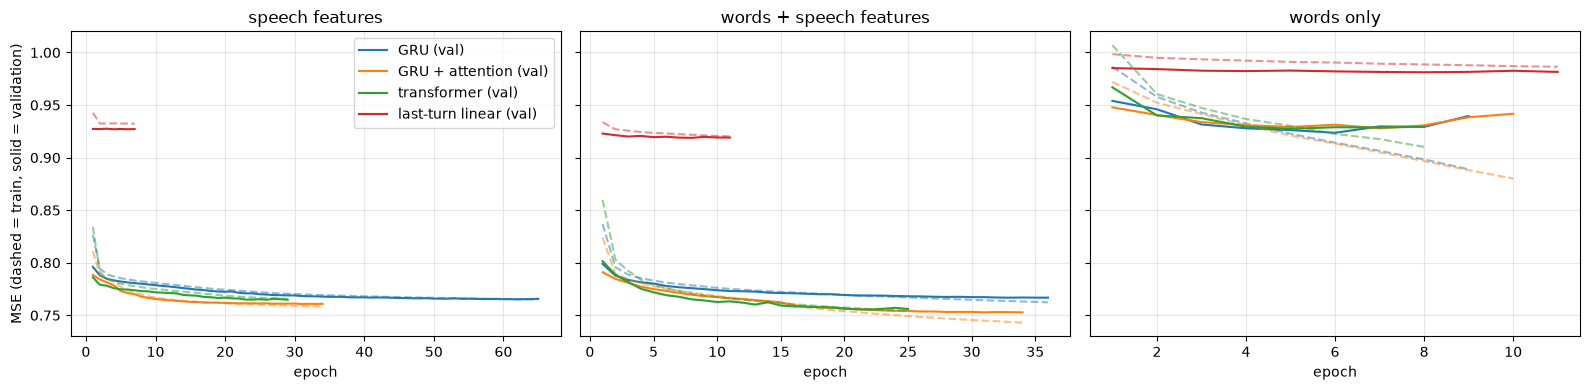

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, version in zip(axes, VERSIONS):
    for architecture in ARCHITECTURES:
        history = histories[f"{architecture} | {version}"]
        line, = ax.plot(history.epoch, history.val, label=f"{architecture} (val)")
        ax.plot(history.epoch, history.train, "--", color=line.get_color(), alpha=0.5)
    ax.set_title(version)
    ax.set_xlabel("epoch")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("MSE (dashed = train, solid = validation)")
axes[0].legend()
plt.tight_layout()
plt.show()

### Which words does the model attend to?

For the best words + speech features model, these are the highest-weighted words in a few test turns.

In [19]:
word_models = {k: v for k, v in models.items() if k.endswith("| words + speech features")}
best_name = min(word_models, key=lambda k: table.loc[(table.version == "words + speech features")
                                                     & (table.model == k.split(" | ")[0]), "val MSE"].item())
id_to_word = {i: w for w, i in vocab.items()} | {UNK_ID: "<unk>"}
batch = to_device(next(iter(loaders["test"])))
size, length = batch["inputs"].shape[:2]
with torch.no_grad():
    _, weights = models[best_name].encoder.words(batch["tokens"], batch["token_turn"], size * length)
print(best_name)
shown = 0
for turn in range(1, length):
    selected = (batch["token_turn"] == turn).nonzero().squeeze(-1)
    if len(selected) < 6:
        continue
    words = [id_to_word[int(t)] for t in batch["tokens"][selected]]
    w = weights[selected].cpu().numpy()
    print(" ".join(f"{word}[{weight:.2f}]" if weight >= np.sort(w)[-2] else word for word, weight in zip(words, w)))
    shown += 1
    if shown == 8:
        break

## 12. Errors on speaker changes vs the same speaker continuing

About a third of turns come from the same person as the turn before. Predicting a turn by the *other* speaker should be harder, since their voice can be quite different, especially in pitch. The models don't know who speaks next, so this breaks the test error down by turn type. It doesn't change the task.

In [20]:
def evaluate_by_turn_type(predict, loader, kind):
    sse, count = torch.zeros(N_FEAT), torch.zeros(N_FEAT)
    with torch.no_grad():
        for batch in loader:
            batch = to_device(batch)
            observed = batch["observed"] & (batch["turn_type"] == kind).unsqueeze(-1)
            with autocast():
                prediction = predict(batch)
            sse += (((prediction.float() - batch["targets"]) ** 2) * observed).sum(dim=(0, 1)).cpu()
            count += observed.sum(dim=(0, 1)).cpu()
    return mse(sse, count)


predictors = dict(baselines) | {name: model for name, model in models.items()}
by_type = pd.DataFrame([{"model": name,
                         "same speaker continues": evaluate_by_turn_type(predict, loaders["test"], 1),
                         "speaker change": evaluate_by_turn_type(predict, loaders["test"], 2)}
                        for name, predict in predictors.items()])
by_type.round(4)

,model,same speaker continues,speaker change
0,training mean,0.9563,1.0560
1,previous turn,1.1813,1.8897
2,GRU | speech features,0.7708,0.7824
3,GRU + attention | speech features,0.7721,0.7738
4,transformer | speech features,0.7993,0.7649
5,last-turn linear | speech features,0.7857,1.0469
6,GRU | words + speech features,0.7467,0.7994
7,GRU + attention | words + speech features,0.7646,0.7664
8,transformer | words + speech features,0.7761,0.7639
9,last-turn linear | words + speech features,0.7827,1.0339


## 13. Extension: isolating the contribution of the words

Comparing speech features with words + speech features gives the gain from adding words to the speech features. Two checks show whether that gain is real.

1. **Paired bootstrap over test conversations.** For each architecture, the test error of "words + speech features" minus that of "speech features", with a 95% confidence interval from resampling the test conversations 1,000 times. Both models are scored on the same conversations, so the comparison is paired. If the interval contains 0, the words add no measurable accuracy.
2. **Word-shuffle test.** At test time, give each turn the words of a random other turn, leaving the speech features untouched. Nothing is retrained. If the error barely rises, the model isn't really using the words. The rise shows how much the trained model relies on them.

In [21]:
def per_conversation_errors(predict, loader, shuffle_words=False, seed=SEED):
    # Sum of squared errors and number of measured values for each test conversation.
    generator = torch.Generator().manual_seed(seed)
    sse, count = [], []
    with torch.no_grad():
        for batch in loader:
            batch = to_device(batch)
            if shuffle_words:
                batch = dict(batch)
                turns_with_words = torch.unique(batch["token_turn"])
                new_place = turns_with_words[torch.randperm(len(turns_with_words), generator=generator).to(device)]
                remap = torch.full((batch["inputs"].shape[0] * batch["inputs"].shape[1],), -1, device=device)
                remap[turns_with_words] = new_place
                batch["token_turn"] = remap[batch["token_turn"]]  # each turn's words move, together, to another turn
            with autocast():
                prediction = predict(batch)
            error = ((prediction.float() - batch["targets"]) ** 2) * batch["observed"]
            sse.append(error.sum(dim=(1, 2)).cpu())
            count.append(batch["observed"].sum(dim=(1, 2)).cpu())
    return torch.cat(sse).numpy(), torch.cat(count).numpy()


rng = np.random.default_rng(SEED)
n_test = len(splits["test"])
resamples = rng.integers(0, n_test, size=(1000, n_test))
rows = []
for architecture in ARCHITECTURES:
    sse_f, count = per_conversation_errors(models[f"{architecture} | speech features"], loaders["test"])
    sse_w, _ = per_conversation_errors(models[f"{architecture} | words + speech features"], loaders["test"])
    difference = sse_w[resamples].sum(1) / count[resamples].sum(1) - sse_f[resamples].sum(1) / count[resamples].sum(1)
    low, high = np.percentile(difference, [2.5, 97.5])
    rows.append({"architecture": architecture, "speech features": sse_f.sum() / count.sum(),
                 "words + speech features": sse_w.sum() / count.sum(),
                 "difference": sse_w.sum() / count.sum() - sse_f.sum() / count.sum(),
                 "95% CI low": low, "95% CI high": high})
print("Test MSE; difference = words + speech features minus speech features (negative = words help)")
display(pd.DataFrame(rows).round(4))

Test MSE; difference = words + speech features minus speech features (negative = words help)


,architecture,speech features,words + speech features,difference,95% CI low,95% CI high
0,GRU,0.7787,0.7808,0.0020,0.0012,0.0028
1,GRU + attention,0.7738,0.7664,-0.0074,-0.0082,-0.0065
2,transformer,0.7781,0.7690,-0.0091,-0.0102,-0.0082
3,last-turn linear,0.9516,0.9422,-0.0094,-0.0108,-0.0081


In [22]:
rows = []
for name, model in models.items():
    if " | words" not in name:
        continue
    sse, count = per_conversation_errors(model, loaders["test"])
    sse_shuffled, _ = per_conversation_errors(model, loaders["test"], shuffle_words=True)
    rows.append({"model": name, "test MSE": sse.sum() / count.sum(),
                 "words shuffled": sse_shuffled.sum() / count.sum()})
shuffle_table = pd.DataFrame(rows)
shuffle_table["increase"] = shuffle_table["words shuffled"] - shuffle_table["test MSE"]
shuffle_table.round(4)

,model,test MSE,words shuffled,increase
0,GRU | words + speech features,0.7808,0.8092,0.0285
1,GRU + attention | words + speech features,0.7664,0.8048,0.0384
2,transformer | words + speech features,0.7690,0.8073,0.0383
3,last-turn linear | words + speech features,0.9422,0.9757,0.0335
4,GRU | words only,0.9460,1.0460,0.1000
5,GRU + attention | words only,0.9455,1.0451,0.0997
6,transformer | words only,0.9485,1.0647,0.1162
7,last-turn linear | words only,1.0105,1.0308,0.0203


## 14. Main question, tuned: can a larger transformer beat the recurrent networks?

The comparison above uses one size per model. Before concluding anything about the transformer, each architecture gets a small search on the main experiment (speech features only):

- **Transformer:** 2 or 4 layers, model size 128 or 256 (feed-forward size twice the model size).
- **GRU and GRU + attention:** hidden size 128 or 256.
- Every run uses a **learning-rate warmup**: the learning rate rises linearly over the first 500 steps (about 2 epochs). Transformers often train badly without one. Both learning rates are tried, as before.
- Each architecture keeps the configuration with the lowest validation loss. Only the kept ones are scored on the test set, and a paired bootstrap (as in section 13) compares the best transformer with each recurrent network.

Every configuration first passes the same causality check as in section 7.

In [23]:
SWEEP_WARMUP = 500  # steps, about 2 epochs
SWEEP = {
    "GRU": [{"hidden": 128}, {"hidden": 256}],
    "GRU + attention": [{"hidden": 128}, {"hidden": 256}],
    "transformer": [{"layers": layers, "dim": dim} for layers in (2, 4) for dim in (128, 256)],
}


def build_sweep_model(architecture, config):
    if architecture == "transformer":
        encoder = TurnEncoder(use_features=True, use_words=False, model_dim=config["dim"])
        return CausalTransformer(encoder, layers=config["layers"], ff_dim=2 * config["dim"]).to(device)
    encoder = TurnEncoder(use_features=True, use_words=False)
    return GRUModel(encoder, hidden=config["hidden"], attention=architecture == "GRU + attention").to(device)


def describe(config):
    return f'{config["layers"]} layers, size {config["dim"]}' if "layers" in config else f'hidden {config["hidden"]}'


for architecture, configs in SWEEP.items():
    for config in configs:
        model = build_sweep_model(architecture, config).cpu().eval()
        with torch.no_grad():
            original = model(check_batch)
            changed = model(perturb_after(check_batch, k))
        assert torch.allclose(original[:, :k + 1], changed[:, :k + 1], atol=1e-5), (architecture, config)
print("causality check passed for every sweep configuration")

sweep_rows, sweep_best = [], {}
for architecture, configs in SWEEP.items():
    for config in configs:
        for lr in LEARNING_RATES:
            print(f"sweep | {architecture} | {describe(config)} | lr {lr:g}")
            model, history, best_epoch = train_model("speech features", architecture, lr, warmup_steps=SWEEP_WARMUP,
                                                     build=lambda: build_sweep_model(architecture, config))
            val_loss = mse(*evaluate(model, loaders["val"]))
            sweep_rows.append({"model": architecture, "configuration": describe(config), "lr": lr,
                               "params": sum(p.numel() for p in model.parameters()),
                               "best epoch": best_epoch, "val MSE": val_loss})
            print(f"  -> sweep val MSE {val_loss:.4f} (best epoch {best_epoch})")
            print()
            if architecture not in sweep_best or val_loss < sweep_best[architecture][0]:
                sweep_best[architecture] = (val_loss, model, describe(config), lr)

causality check passed for every sweep configuration
sweep | GRU | hidden 128 | lr 0.001


  epoch  1  train 0.8655  val 0.7972  (4s)


  epoch  2  train 0.7931  val 0.7859  (4s)


  epoch  3  train 0.7863  val 0.7823  (4s)


  epoch  4  train 0.7834  val 0.7800  (4s)


  epoch  5  train 0.7815  val 0.7785  (4s)


... (396 outputs left out)

  epoch 21  train 0.7611  val 0.7638  (8s)


  epoch 22  train 0.7606  val 0.7634  (9s)


  epoch 23  train 0.7599  val 0.7632  (9s)


  -> sweep val MSE 0.7626 (best epoch 20)



In [24]:
sweep_table = pd.DataFrame(sweep_rows)
print("Every configuration (validation only):")
display(sweep_table.round(4))

kept = []
for architecture, (val_loss, model, configuration, lr) in sweep_best.items():
    test_sse, test_count = evaluate(model, loaders["test"])
    kept.append({"model": architecture, "configuration": configuration, "lr": lr, "val MSE": val_loss,
                 "test MSE": mse(test_sse, test_count),
                 "error removed vs mean": f"{1 - mse(test_sse, test_count) / mean_mse:.1%}"})
print("Kept configuration per model (chosen on validation), scored on the test set:")
display(pd.DataFrame(kept).round(4))

sse_t, count = per_conversation_errors(sweep_best["transformer"][1], loaders["test"])
rows = []
for architecture in ("GRU", "GRU + attention"):
    sse_r, _ = per_conversation_errors(sweep_best[architecture][1], loaders["test"])
    difference = sse_t[resamples].sum(1) / count[resamples].sum(1) - sse_r[resamples].sum(1) / count[resamples].sum(1)
    low, high = np.percentile(difference, [2.5, 97.5])
    rows.append({"comparison": f"transformer minus {architecture}",
                 "difference": sse_t.sum() / count.sum() - sse_r.sum() / count.sum(),
                 "95% CI low": low, "95% CI high": high})
print("Test MSE difference, tuned models (negative = the transformer is better):")
display(pd.DataFrame(rows).round(4))

Every configuration (validation only):


,model,configuration,lr,params,best epoch,val MSE
0,GRU,hidden 128,0.0010,102151,25,0.7651
1,GRU,hidden 128,0.0003,102151,54,0.7656
2,GRU,hidden 256,0.0010,300423,16,0.7649
3,GRU,hidden 256,0.0003,300423,33,0.7648
4,GRU + attention,hidden 128,0.0010,119431,13,0.7612
5,GRU + attention,hidden 128,0.0003,119431,35,0.7608
6,GRU + attention,hidden 256,0.0010,367751,10,0.7610
7,GRU + attention,hidden 256,0.0003,367751,16,0.7609
8,transformer,"2 layers, size 128",0.0010,268295,16,0.7653
9,transformer,"2 layers, size 128",0.0003,268295,38,0.7630


Kept configuration per model (chosen on validation), scored on the test set:


,model,configuration,lr,val MSE,test MSE,error removed vs mean
0,GRU,hidden 256,0.0003,0.7648,0.7783,23.6%
1,GRU + attention,hidden 128,0.0003,0.7608,0.7737,24.1%
2,transformer,"4 layers, size 256",0.0003,0.7626,0.7760,23.9%


Test MSE difference, tuned models (negative = the transformer is better):


,comparison,difference,95% CI low,95% CI high
0,transformer minus GRU,-0.0023,-0.0029,-0.0017
1,transformer minus GRU + attention,0.0023,0.0018,0.0029


## 15. What the results say

### Main question: can a transformer beat the recurrent networks?

**Not on this task.** After tuning each architecture on size and learning rate, with warmup, and choosing on validation (section 14):

| tuned model | parameters | test MSE |
|---|---|---|
| GRU + attention (hidden 128) | 119k | **0.7737** |
| transformer (4 layers, size 256) | 2.1M | 0.7760 |
| GRU (hidden 256) | 300k | 0.7783 |

- The transformer beats the plain GRU by 0.0023 (95% CI −0.0029 to −0.0017), but loses to the GRU with attention by 0.0023 (CI +0.0018 to +0.0029), a model with about 18 times fewer parameters.
- All three remove about 24% of the error of predicting the mean, so the gaps between them are small, about 0.3% of the error. The intervals cover the sampling of test conversations, not training randomness. Retraining the same model moved its test MSE by up to 0.001, so the ordering is suggestive rather than settled.
- Size barely mattered. Across the sweep, validation MSE varied by at most 0.005 for the transformer and 0.001 for the GRUs. More capacity doesn't help, which suggests the limit is what the 7 features of past turns can predict, not the size of the models.

**Where the transformer differs.** It has the lowest error when the speaker changes (0.765, against 0.774 for GRU + attention and 0.782 for the GRU) and the highest when the same speaker continues (0.799, against 0.771–0.772). A possible reason, not tested here: attention can look up the other speaker's earlier turns directly, while a GRU's state is dominated by the most recent turn, which is the right one to follow when the same person keeps talking.

**The conversation history matters more than the last turn.** The last-turn linear model removes only 6.7% of the error, against about 24% for the sequence models. It does well when the same speaker continues (0.786) but is worse than the mean at speaker changes (1.047), because then the last turn is from the other person. Most of what the sequence models predict comes from how each speaker has sounded earlier in the conversation.

**Half precision.** bf16 autocast gave no speed-up at these model sizes: 0.7–1.0× the speed of fp32.

### Extension: do the words add anything?

- **Speech features vs words only.** The speech features remove about 24% of the error. The words alone remove about 7% with the sequence models and under 1% from the last turn alone. They mostly help with pitch mean and speaking rate.
- **Words on top of the speech features.** A small but measurable gain for the models with attention: −0.0074 for GRU + attention (CI −0.0082 to −0.0065) and −0.0091 for the transformer (CI −0.0102 to −0.0082). The last-turn linear model gains −0.0094. The plain GRU gets slightly worse (+0.0020, CI +0.0012 to +0.0028).
- **The models use the words.** Shuffling the words at test time raises the error of every model that has them (+0.029 to +0.038 with speech features). But the gain from words is about 1% of the error: the speech features carry nearly all of the predictable information.

### Limits

- One split and one training seed per configuration.
- Every model trained until validation loss stopped improving (at most 100 epochs; the latest best epoch was 62).
- The sweep covered model size and learning rate, with warmup. Other choices, such as dropout or the positional encoding, were not explored.